# Lab 4: Regression Analysis with Regularization Techniques
**Student:** Vineela Reddy Karnatakam  
**Course:** MSCS-634 — Advanced Big Data and Data Mining  
**Assignment:** Lab 4 — Regression Analysis with Regularization Techniques

**Dataset:** Scikit-learn Diabetes dataset. **Objective:** Predict the quantitative diabetes disease-progression target by comparing simple linear, multiple linear, polynomial, Ridge, and Lasso regression. Data are for learning, not clinical predictions.

## 1. Data preparation and exploration
Use a consistent random 80/20 train/test split (`random_state=42`) for fair comparisons. The ten predictors are already mean-centered and scaled by scikit-learn; we still put `StandardScaler` inside Ridge/Lasso pipelines for a transparent regularization workflow without test-set leakage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option('display.precision', 3)
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()
print('Predictors:', list(X.columns))
print('Dataset shape:', X.shape, '| target shape:', y.shape)
print('Target description:', diabetes.DESCR.split('Target:')[-1][:400] if 'Target:' in diabetes.DESCR else 'Quantitative disease progression at one year')
display(X.head())
display(y.describe().to_frame('disease_progression'))
print('Missing values:', int(X.isna().sum().sum() + y.isna().sum()))
print('Duplicate feature rows:', int(X.duplicated().sum()))
print('Feature summary:')
display(X.describe().T[['mean','std','min','max']])

Predictors: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Dataset shape: (442, 10) | target shape: (442,)
Target description:  Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5     


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038,0.051,0.062,0.022,-0.044,-0.035,-0.043,-0.003,0.020,-0.018
1,-0.002,-0.045,-0.051,-0.026,-0.008,-0.019,0.074,-0.039,-0.068,-0.092
2,0.085,0.051,0.044,-0.006,-0.046,-0.034,-0.032,-0.003,0.003,-0.026
3,-0.089,-0.045,-0.012,-0.037,0.012,0.025,-0.036,0.034,0.023,-0.009
4,0.005,-0.045,-0.036,0.022,0.004,0.016,0.008,-0.003,-0.032,-0.047


,disease_progression
count,442.000
mean,152.133
std,77.093
min,25.000
25%,87.000
50%,140.500
75%,211.500
max,346.000


Missing values: 0
Duplicate feature rows: 0
Feature summary:


,mean,std,min,max
age,-2.512e-19,0.048,-0.107,0.111
sex,1.231e-17,0.048,-0.045,0.051
bmi,-2.246e-16,0.048,-0.090,0.171
bp,-4.798e-17,0.048,-0.112,0.132
s1,-1.381e-17,0.048,-0.127,0.154
s2,3.918e-17,0.048,-0.116,0.199
s3,-5.777e-18,0.048,-0.102,0.181
s4,-9.043e-18,0.048,-0.076,0.185
s5,9.269e-17,0.048,-0.126,0.134
s6,1.130e-17,0.048,-0.138,0.136


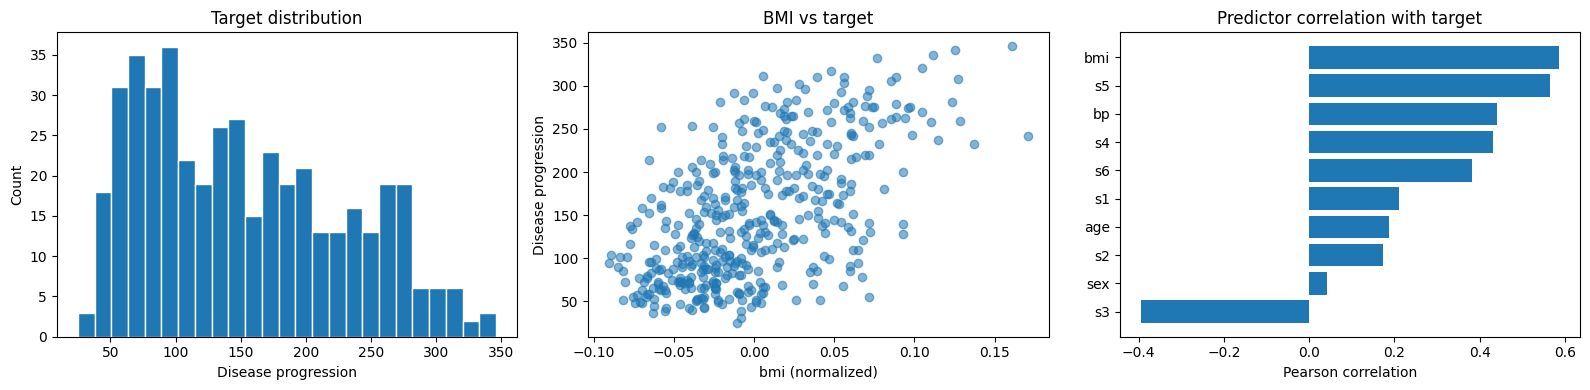

Top target correlations:


,correlation
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s3,-0.395
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(y, bins=25, edgecolor='white')
axes[0].set(title='Target distribution', xlabel='Disease progression', ylabel='Count')
axes[1].scatter(X['bmi'], y, alpha=.55)
axes[1].set(title='BMI vs target', xlabel='bmi (normalized)', ylabel='Disease progression')
correlations = X.assign(target=y).corr()['target'].drop('target').sort_values()
axes[2].barh(correlations.index, correlations.values)
axes[2].set(title='Predictor correlation with target', xlabel='Pearson correlation')
plt.tight_layout(); plt.show()
print('Top target correlations:'); display(correlations.reindex(correlations.abs().sort_values(ascending=False).index).to_frame('correlation'))

**Data quality decisions:** Check missing values and duplicate feature vectors rather than automatically dropping observations; repeated patient measurements are not necessarily errors. No imputation is required when the reported missing count is zero. No outlier removal is performed, because extreme target values may be genuine and indiscriminate removal could bias the exercise.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f'Train: {len(X_train)} | Test: {len(X_test)}')
results = []
predictions = {}

def record(name, model, x_train, x_test):
    model.fit(x_train, y_train)
    yhat_train = model.predict(x_train)
    yhat_test = model.predict(x_test)
    mse = mean_squared_error(y_test, yhat_test)
    result = {'Model': name, 'Train R²': r2_score(y_train, yhat_train),
              'Test MAE': mean_absolute_error(y_test, yhat_test),
              'Test MSE': mse, 'Test RMSE': np.sqrt(mse),
              'Test R²': r2_score(y_test, yhat_test),
              'R² gap (train-test)': r2_score(y_train, yhat_train) - r2_score(y_test, yhat_test)}
    results.append(result)
    predictions[name] = np.asarray(yhat_test)
    return model

def actual_vs_predicted(names, heading):
    fig, axes = plt.subplots(1, len(names), figsize=(5.2*len(names), 4.5), squeeze=False)
    for ax, name in zip(axes.ravel(), names):
        ax.scatter(y_test, predictions[name], alpha=.55)
        lo = min(y_test.min(), predictions[name].min())
        hi = max(y_test.max(), predictions[name].max())
        ax.plot([lo, hi], [lo, hi], 'k--', linewidth=1, label='Perfect fit')
        ax.set(title=name, xlabel='Actual target', ylabel='Predicted target')
        ax.legend()
    fig.suptitle(heading)
    plt.tight_layout(); plt.show()

Train: 353 | Test: 89


## 2. Simple linear regression
Use only `bmi` as the independent variable. Keep the same row-level split as other approaches.

,Model,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,R² gap (train-test)
0,Simple Linear (bmi),0.366,52.26,4061.826,63.732,0.233,0.132


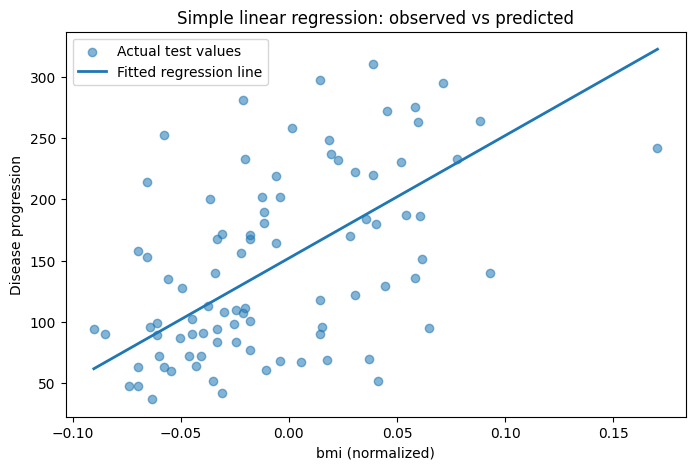

In [4]:
simple = record('Simple Linear (bmi)', LinearRegression(), X_train[['bmi']], X_test[['bmi']])
display(pd.DataFrame(results).tail(1))
order = np.argsort(X_test['bmi'].to_numpy())
plt.figure(figsize=(8,5))
plt.scatter(X_test['bmi'], y_test, alpha=.55, label='Actual test values')
plt.plot(X_test['bmi'].to_numpy()[order], predictions['Simple Linear (bmi)'][order],
         linewidth=2, label='Fitted regression line')
plt.xlabel('bmi (normalized)'); plt.ylabel('Disease progression')
plt.title('Simple linear regression: observed vs predicted'); plt.legend(); plt.show()

## 3. Multiple linear regression
Fit a single ordinary least squares regression using all ten features; compare test predictions with actual values.

,Model,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,R² gap (train-test)
1,Multiple Linear (10 features),0.528,42.794,2900.194,53.853,0.453,0.075


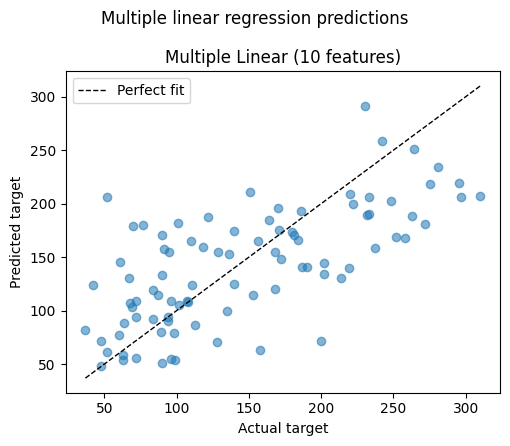

In [5]:
multiple = record('Multiple Linear (10 features)', LinearRegression(), X_train, X_test)
display(pd.DataFrame(results).tail(1))
actual_vs_predicted(['Multiple Linear (10 features)'], 'Multiple linear regression predictions')

## 4. Polynomial regression
Apply polynomial features **only to `bmi`**, varying degree 1, 2, 3, 5, and 8. This keeps polynomial complexity interpretable and reduces the risk of an excessively large design matrix. We separately compare against the ten-feature multiple linear regression. High-degree polynomials can overfit badly; compare training and held-out test R² rather than relying on training accuracy alone.

,Model,Train R²,Test R²,Test RMSE,R² gap (train-test)
2,"Polynomial (bmi, degree=1)",0.366,0.233,63.732,0.132
3,"Polynomial (bmi, degree=2)",0.367,0.229,63.914,0.138
4,"Polynomial (bmi, degree=3)",0.367,0.233,63.753,0.134
5,"Polynomial (bmi, degree=5)",0.371,0.229,63.921,0.142
6,"Polynomial (bmi, degree=8)",0.385,-0.486,88.743,0.872


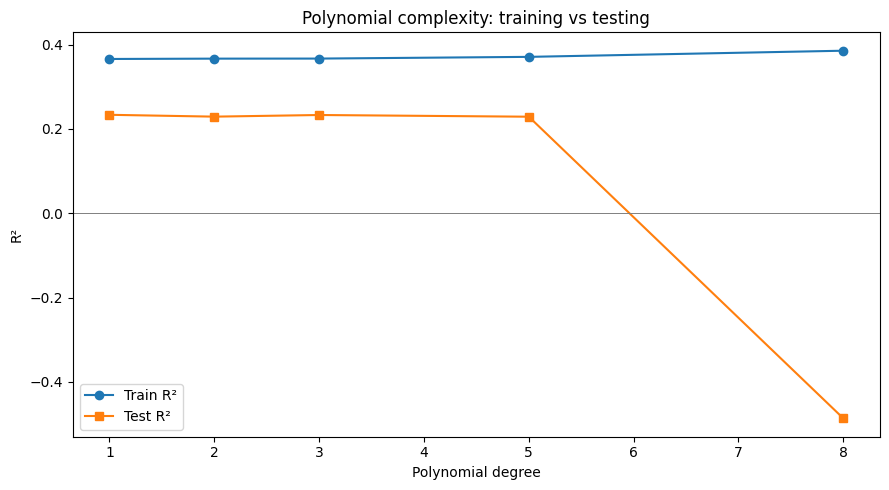

In [6]:
degrees = [1, 2, 3, 5, 8]
for degree in degrees:
    name = f'Polynomial (bmi, degree={degree})'
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
    record(name, model, X_train[['bmi']], X_test[['bmi']])
poly_table = pd.DataFrame(results).query('Model.str.startswith("Polynomial")', engine='python')
display(poly_table[['Model', 'Train R²', 'Test R²', 'Test RMSE', 'R² gap (train-test)']])
plt.figure(figsize=(9,5))
plt.plot(degrees, poly_table['Train R²'], marker='o', label='Train R²')
plt.plot(degrees, poly_table['Test R²'], marker='s', label='Test R²')
plt.axhline(0, color='gray', lw=.7)
plt.xlabel('Polynomial degree'); plt.ylabel('R²'); plt.title('Polynomial complexity: training vs testing')
plt.legend(); plt.tight_layout(); plt.show()

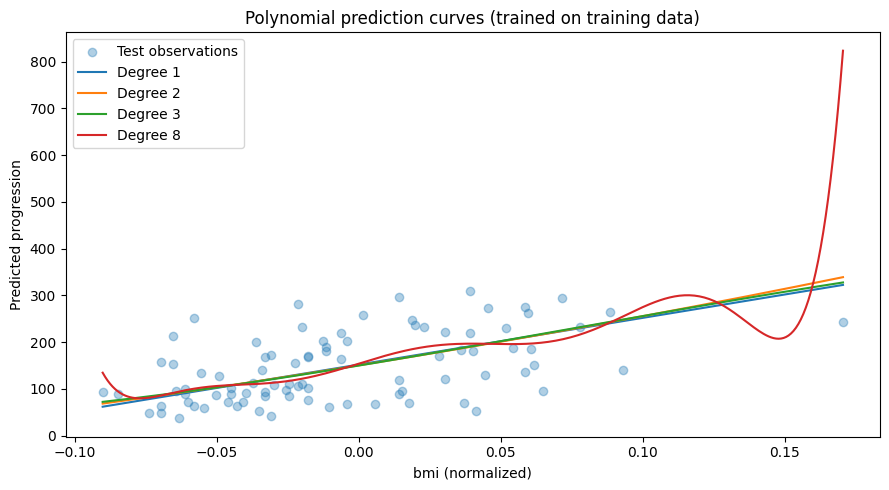

In [7]:
bmi_grid = np.linspace(X['bmi'].min(), X['bmi'].max(), 300).reshape(-1,1)
plt.figure(figsize=(9,5))
plt.scatter(X_test['bmi'], y_test, alpha=.35, label='Test observations')
for degree in [1, 2, 3, 8]:
    poly = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
    poly.fit(X_train[['bmi']], y_train)
    plt.plot(bmi_grid.ravel(), poly.predict(pd.DataFrame(bmi_grid, columns=['bmi'])),
             label=f'Degree {degree}')
plt.xlabel('bmi (normalized)'); plt.ylabel('Predicted progression')
plt.title('Polynomial prediction curves (trained on training data)')
plt.legend(); plt.tight_layout(); plt.show()

## 5. Ridge and Lasso regularization
For each method, explore `alpha` = 0.01, 0.1, 1, 10, 100. Larger `alpha` strengthens the penalty. Ridge applies an L2 penalty and usually shrinks all coefficients smoothly; Lasso applies an L1 penalty and can set coefficients exactly to zero. Scale predictors **inside each pipeline**, fitting the scaler on training data only. Alpha exploration here is descriptive: we do **not** select a winning alpha based on test-set performance; a production workflow would tune alpha via cross-validation on training data.

In [8]:
alphas = [0.01, 0.1, 1, 10, 100]
coefficient_records = []
for kind in ['Ridge', 'Lasso']:
    for alpha in alphas:
        estimator = Ridge(alpha=alpha) if kind == 'Ridge' else Lasso(alpha=alpha, max_iter=100000)
        pipeline = make_pipeline(StandardScaler(), estimator)
        name = f'{kind} (alpha={alpha:g})'
        record(name, pipeline, X_train, X_test)
        betas = pipeline[-1].coef_
        coefficient_records.append({'Method':kind, 'alpha':alpha,
                                    'Coefficient L1 norm':np.abs(betas).sum(),
                                    'Nonzero coefficients':int(np.sum(np.abs(betas)>1e-7))})
regularization_table = pd.DataFrame(results)[pd.DataFrame(results)['Model'].str.startswith(('Ridge','Lasso'))]
display(regularization_table[['Model','Train R²','Test MAE','Test MSE','Test RMSE','Test R²']])
display(pd.DataFrame(coefficient_records))

,Model,Train R²,Test MAE,Test MSE,Test RMSE,Test R²
7,Ridge (alpha=0.01),0.528,42.794,2900.075,53.852,0.453
8,Ridge (alpha=0.1),0.528,42.796,2899.055,53.843,0.453
9,Ridge (alpha=1),0.528,42.812,2892.015,53.777,0.454
10,Ridge (alpha=10),0.525,42.857,2875.779,53.626,0.457
11,Ridge (alpha=100),0.512,43.251,2858.224,53.462,0.461
12,Lasso (alpha=0.01),0.528,42.795,2898.368,53.836,0.453
13,Lasso (alpha=0.1),0.527,42.805,2884.624,53.709,0.456
14,Lasso (alpha=1),0.523,42.803,2824.568,53.147,0.467
15,Lasso (alpha=10),0.465,44.765,2933.835,54.165,0.446
16,Lasso (alpha=100),0.000,64.006,5361.533,73.222,-0.012


,Method,alpha,Coefficient L1 norm,Nonzero coefficients
0,Ridge,0.01,182.772,10
1,Ridge,0.10,179.738,10
2,Ridge,1.00,156.418,10
3,Ridge,10.00,108.704,10
4,Ridge,100.00,89.645,10
5,Lasso,0.01,178.899,10
6,Lasso,0.10,140.960,10
7,Lasso,1.00,97.269,9
8,Lasso,10.00,53.621,4
9,Lasso,100.00,0.000,0


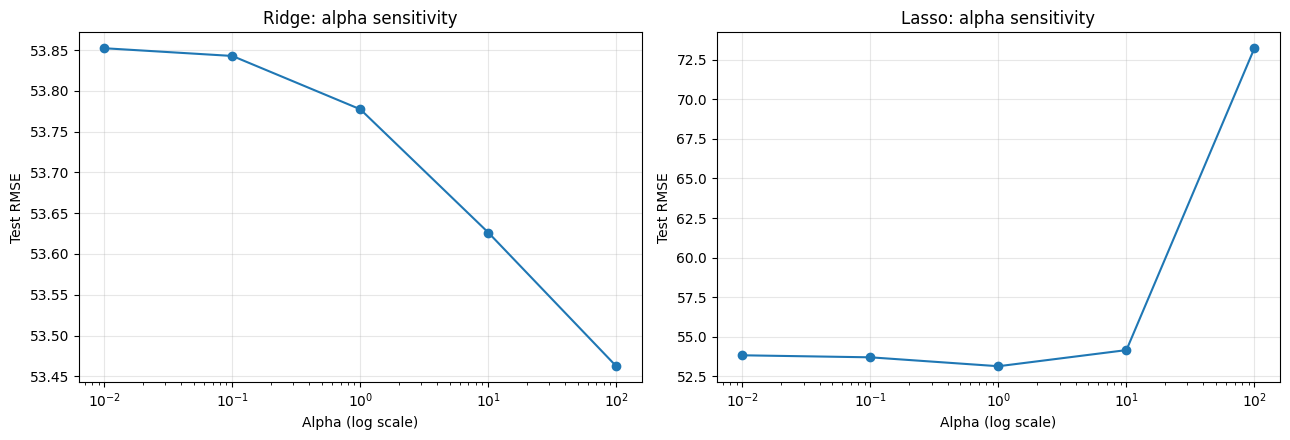

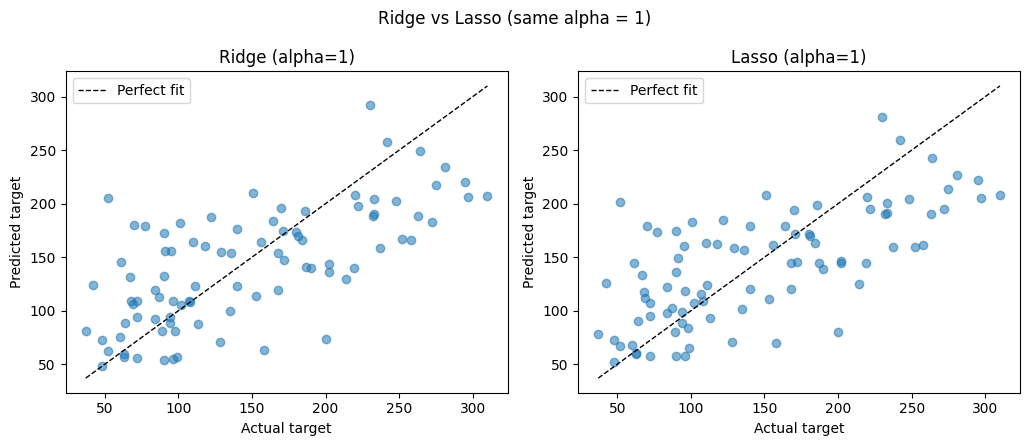

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
for ax, kind in zip(axes, ['Ridge','Lasso']):
    rows = regularization_table[regularization_table['Model'].str.startswith(kind)]
    ax.plot(alphas, rows['Test RMSE'], marker='o', label='Test RMSE')
    ax.set(xscale='log', xlabel='Alpha (log scale)', ylabel='Test RMSE', title=f'{kind}: alpha sensitivity')
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
actual_vs_predicted(['Ridge (alpha=1)', 'Lasso (alpha=1)'], 'Ridge vs Lasso (same alpha = 1)')

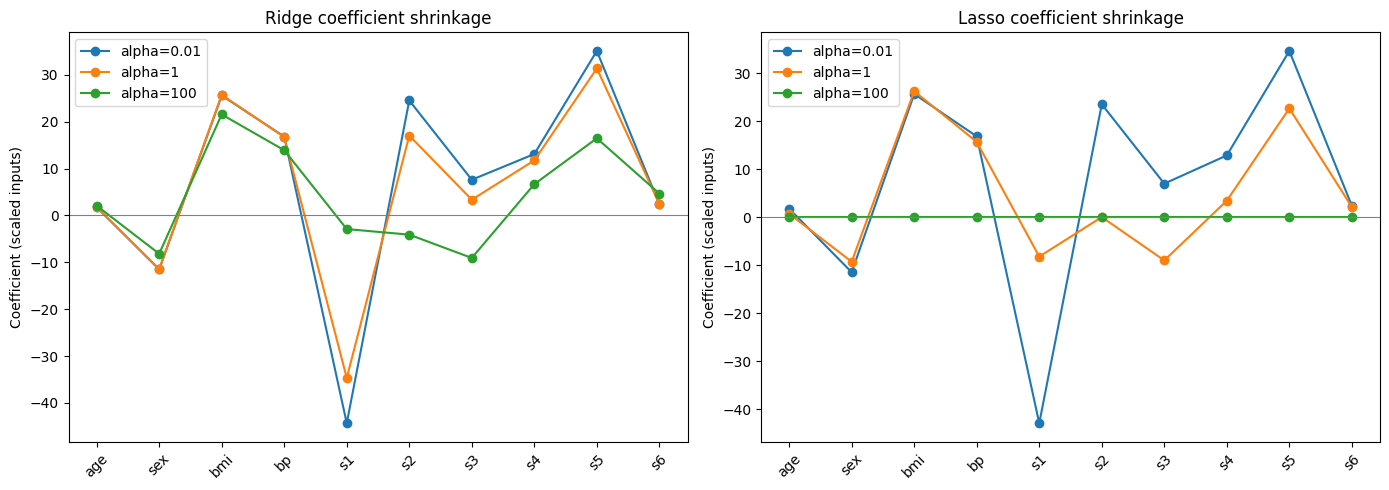

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
for ax, kind in zip(axes, ['Ridge', 'Lasso']):
    for alpha in [0.01,1,100]:
        estimator = Ridge(alpha=alpha) if kind == 'Ridge' else Lasso(alpha=alpha,max_iter=100000)
        pipe = make_pipeline(StandardScaler(), estimator)
        pipe.fit(X_train,y_train)
        ax.plot(X.columns, pipe[-1].coef_,marker='o',label=f'alpha={alpha:g}')
    ax.axhline(0,color='gray',linewidth=.8)
    ax.set(title=f'{kind} coefficient shrinkage',ylabel='Coefficient (scaled inputs)')
    ax.tick_params(axis='x',rotation=45)
    ax.legend()
plt.tight_layout();plt.show()

## 6. Model comparison and analysis
We report **test** MAE, MSE, RMSE (lower is better) and R² (higher is better), plus train/test R² gap for signs of overfitting. Since test data are reused for descriptive comparisons, the apparent best test model is not an unbiased estimate of the result of model selection.

In [11]:
comparison = pd.DataFrame(results).sort_values('Test RMSE').reset_index(drop=True)
display(comparison.round(3))
print('Lowest held-out RMSE (descriptive only):', comparison.loc[0,'Model'])
print('  RMSE:', round(comparison.loc[0,'Test RMSE'],3), 'R²:',round(comparison.loc[0,'Test R²'],3))
print('Best polynomial test R²:', poly_table.loc[poly_table['Test R²'].idxmax(), 'Model'])
print('Worst polynomial generalization gap:', poly_table.loc[poly_table['R² gap (train-test)'].idxmax(), 'Model'])

,Model,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,R² gap (train-test)
0,Lasso (alpha=1),0.523,42.803,2824.568,53.147,0.467,0.056
1,Ridge (alpha=100),0.512,43.251,2858.224,53.462,0.461,0.051
2,Ridge (alpha=10),0.525,42.857,2875.779,53.626,0.457,0.068
3,Lasso (alpha=0.1),0.527,42.805,2884.624,53.709,0.456,0.072
4,Ridge (alpha=1),0.528,42.812,2892.015,53.777,0.454,0.073
5,Lasso (alpha=0.01),0.528,42.795,2898.368,53.836,0.453,0.075
6,Ridge (alpha=0.1),0.528,42.796,2899.055,53.843,0.453,0.075
7,Ridge (alpha=0.01),0.528,42.794,2900.075,53.852,0.453,0.075
8,Multiple Linear (10 features),0.528,42.794,2900.194,53.853,0.453,0.075
9,Lasso (alpha=10),0.465,44.765,2933.835,54.165,0.446,0.019


Lowest held-out RMSE (descriptive only): Lasso (alpha=1)
  RMSE: 53.147 R²: 0.467
Best polynomial test R²: Polynomial (bmi, degree=1)
Worst polynomial generalization gap: Polynomial (bmi, degree=8)


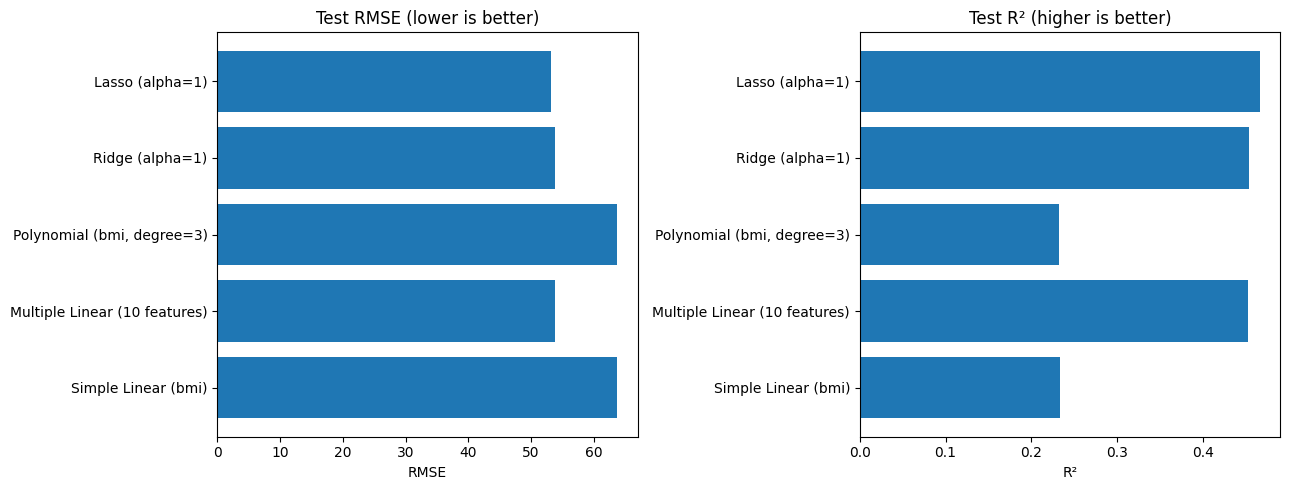

In [12]:
selected = ['Simple Linear (bmi)', 'Multiple Linear (10 features)',
            'Polynomial (bmi, degree=3)', 'Ridge (alpha=1)', 'Lasso (alpha=1)']
summary = pd.DataFrame(results).set_index('Model').loc[selected]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(summary.index,summary['Test RMSE'])
axes[0].set(title='Test RMSE (lower is better)', xlabel='RMSE')
axes[1].barh(summary.index,summary['Test R²'])
axes[1].set(title='Test R² (higher is better)', xlabel='R²')
plt.tight_layout();plt.show()

### Conclusions
- **Simple versus multiple regression:** The one-feature BMI model captures only part of the relationship; using all ten features can improve predictive power, although correlated variables can make coefficients unstable.
- **Polynomial complexity:** Compare degree-specific train/test R² above. Greater training fit does not guarantee better held-out performance; severe positive train-test gaps are evidence of overfitting.
- **Ridge versus Lasso:** Ridge shrinks coefficients via L2 regularization, while Lasso may zero out coefficients via L1 regularization. The alpha charts show the bias-variance tradeoff: too much penalty can underfit.
- **Diabetes dataset:** The target is continuous, and predictors have varying strengths of association. The models demonstrate associations, **not** causal effects or clinical validity.
- **Caveat:** A single 80/20 split has sampling variability. For deployable selection, use a cross-validated hyperparameter search on the training set and evaluate the locked model only once on a held-out test set.

**Reproducibility:** Fixed random seed (`42`), built-in dataset, and dependency list in README.